# Data availability report
Decision-neutral evidence for the modeling-window meeting.

In [1]:
from pathlib import Path
import pandas as pd
pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)
pd.set_option('display.width', None)
import matplotlib.pyplot as plt
root=Path.cwd().resolve()
while root!=root.parent and not (root/'data'/'raw').exists(): root=root.parent
raw=root/'data'/'raw'; t={p.stem:pd.read_csv(p,dtype=str,keep_default_na=False) for p in raw.glob('*.csv')}
r=t['races'].copy(); r['year']=pd.to_numeric(r.year); y=r.set_index('raceId').year
x=t['results'].copy(); x['year']=x.raceId.map(y); x['grid_n']=pd.to_numeric(x.grid,errors='coerce'); x['laps_n']=pd.to_numeric(x.laps,errors='coerce'); x['pos_n']=pd.to_numeric(x.positionOrder,errors='coerce'); x['started']=(x.grid_n>0)|((x.grid_n==0)&(x.laps_n>0)); x['podium']=x.pos_n.le(3)
q=t['qualifying'].copy(); q['year']=q.raceId.map(y); s=t['sprint_results'].copy(); s['year']=s.raceId.map(y)
valid=lambda z:(~z.isin(['',r'\N'])).sum(); rows=[]
for year in range(int(r.year.min()),int(r.year.max())+1):
    a=x[x.year.eq(year)]; b=q[q.year.eq(year)]; c=s[s.year.eq(year)]
    rows.append({'year':year,'races':r.loc[r.year.eq(year),'raceId'].nunique(),'result_rows':len(a),'starters':int(a.started.sum()),'podiums':int((a.started&a.podium).sum()),'qualifying_rows':len(b),'quali_position':int(valid(b.position)),'q1':int(valid(b.q1)),'q2':int(valid(b.q2)),'q3':int(valid(b.q3)),'sprint_rows':len(c)})
coverage=pd.DataFrame(rows)
# era totals: sum the counts only (summing year or *_pct is meaningless), then recompute shares
era=coverage.drop(columns='year').groupby(pd.cut(coverage.year,[1949,1993,2002,2013,2024],labels=['1950-1993','1994-2002','2003-2013','2014-2024']),observed=True).sum()
for df in (coverage,era):
    for col in ['quali_position','q1','q2','q3']: df[col+'_pct']=(df[col]/df.result_rows).round(3)
display(coverage); display(era)

,year,races,result_rows,starters,podiums,qualifying_rows,quali_position,q1,q2,q3,sprint_rows,quali_position_pct,q1_pct,q2_pct,q3_pct
0,1950,7,160,160,22,0,0,0,0,0,0,0.000,0.000,0.000,0.000
1,1951,8,179,179,28,0,0,0,0,0,0,0.000,0.000,0.000,0.000
2,1952,8,215,203,24,0,0,0,0,0,0,0.000,0.000,0.000,0.000
3,1953,9,246,246,29,0,0,0,0,0,0,0.000,0.000,0.000,0.000
4,1954,9,230,227,29,0,0,0,0,0,0,0.000,0.000,0.000,0.000
5,1955,7,180,173,27,0,0,0,0,0,0,0.000,0.000,0.000,0.000
6,1956,8,190,182,29,0,0,0,0,0,0,0.000,0.000,0.000,0.000
7,1957,8,171,166,25,0,0,0,0,0,0,0.000,0.000,0.000,0.000
8,1958,11,241,224,33,0,0,0,0,0,0,0.000,0.000,0.000,0.000
9,1959,9,195,179,27,0,0,0,0,0,0,0.000,0.000,0.000,0.000


,races,result_rows,starters,podiums,qualifying_rows,quali_position,q1,q2,q3,sprint_rows,quali_position_pct,q1_pct,q2_pct,q3_pct
year,,,,,,,,,,,,,,
1950-1993,548,14401,12893,1666,0,0,0,0,0,0,0.000,0.000,0.000,0.000
1994-2002,149,3388,3344,447,1548,1548,1516,0,0,0,0.457,0.447,0.000,0.000
2003-2013,200,4344,4337,600,4336,4336,4263,2459,1416,0,0.998,0.981,0.566,0.326
2014-2024,228,4626,4619,684,4610,4610,4559,3388,2213,360,0.997,0.986,0.732,0.478


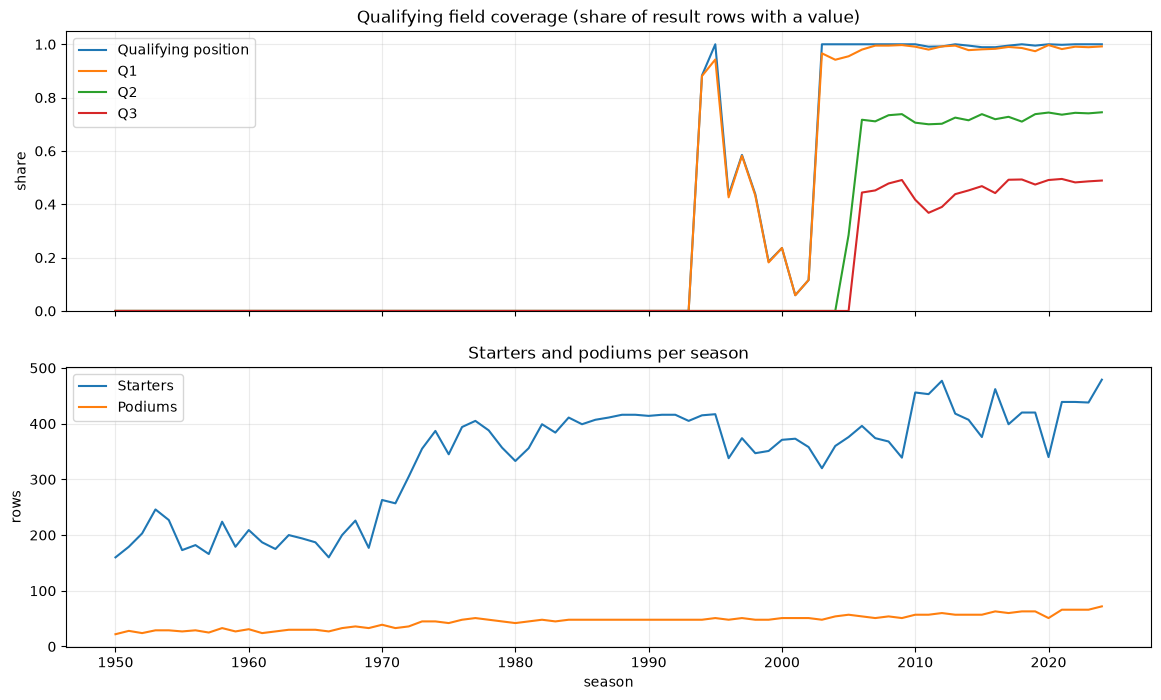

In [2]:
fig,ax=plt.subplots(2,1,figsize=(14,8),sharex=True)
for col,label in [('quali_position_pct','Qualifying position'),('q1_pct','Q1'),('q2_pct','Q2'),('q3_pct','Q3')]: ax[0].plot(coverage.year,coverage[col],label=label)
ax[0].set_ylim(0,1.05); ax[0].set_title('Qualifying field coverage (share of result rows with a value)'); ax[0].set_ylabel('share'); ax[0].legend(); ax[0].grid(alpha=.25); ax[1].plot(coverage.year,coverage.starters,label='Starters'); ax[1].plot(coverage.year,coverage.podiums,label='Podiums'); ax[1].set_title('Starters and podiums per season'); ax[1].set_ylabel('rows'); ax[1].set_xlabel('season'); ax[1].legend(); ax[1].grid(alpha=.25); plt.show()

Note: `result_rows` counts every entry, including non-starters (DNQ/DNPQ) and the 1950-1978 shared-drive duplicates, so shares are per entry, not per starter.
